# Diff-in-Disc Model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import statsmodels.formula.api as smf
from rdrobust import rdrobust

In [2]:
# Disable scientific notation for pandas and numpy in this notebook
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
np.set_printoptions(suppress=True)

In [3]:
# Import the cleaned data frame
df = pd.read_csv('df_rdd_clean.csv', dtype={'code_commune': str})
df['code_commune'] = df['code_commune'].str.zfill(5)   # re-enforce padding after every import

# 2008 has no treated units so I drop it here
df = df[df['election_year'] != 2008].copy()

print(df['election_year'].value_counts())

election_year
2014    513
2020    285
Name: count, dtype: int64


In [4]:
# Build a stacked pre/post panel data frame for the diff-in-disc model

# "pre": outcome measured before the term starts (here it should show NO discontinuity if design is valid)
pre = df.copy()
pre['y'] = pre['skill_share_pre']
pre['post'] = 0

# "post": outcome after the term, discontinuity here (net of pre) = causal effect
post = df.copy()
post['y'] = post['skill_share_pre'] + post['delta_skill_share']
post['post'] = 1

long = pd.concat([pre, post], ignore_index=True)

In [5]:
# Regression model: y ~ d_50 * treat * post

# treat*post is the parameter of interest: the jump in the treatment effect from pre to post,
# netting out any level jump that already existed before treatment (sorting/imbalance at cutoff)
for cyc in [2014, 2020]:
    sub = long[long['election_year'] == cyc]
    m = smf.ols('y ~ d_50 * treat * post', data=sub).fit(
        cov_type='cluster', cov_kwds={'groups': sub['code_commune']}
    )
    print(f"--- {cyc} ---")
    print(m.summary().tables[1])
    print(f"Diff-in-Disc (treat:post): {m.params['treat:post']:.4f}, "
          f"p = {m.pvalues['treat:post']:.3f}, communes = {sub['code_commune'].nunique()}\n")

--- 2014 ---
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.3847      0.005     70.480      0.000       0.374       0.395
d_50                0.0021      0.000      4.808      0.000       0.001       0.003
treat              -0.0552      0.016     -3.456      0.001      -0.087      -0.024
d_50:treat         -0.0172      0.009     -2.001      0.045      -0.034      -0.000
post                0.0395      0.001     50.011      0.000       0.038       0.041
d_50:post           0.0001      0.000      1.203      0.229   -8.56e-05       0.000
treat:post         -0.0018      0.006     -0.316      0.752      -0.013       0.010
d_50:treat:post     0.0004      0.002      0.183      0.855      -0.004       0.005
Diff-in-Disc (treat:post): -0.0018, p = 0.752, communes = 513

--- 2020 ---
                      coef    std err          z      P>|z|      [0.025

In [6]:
# Robustness check: pre-period skill share should show no discontinuity at the cutoff (d_50 = 0) (placebo test)

for cyc in [2014, 2020]:
    sub = df[df['election_year'] == cyc]
    rd_pre = rdrobust(y=sub['skill_share_pre'], x=sub['d_50'], c=0)
    print(rd_pre)

Call: rdrobust

Sharp RD estimates using local polynomial regression.

Number of Observations:                   513
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations           500         13
Number of Unique Obs.            500         13
Number of Effective Obs.          47          7
Bandwidth Estimation           0.907      0.907
Bandwidth Bias                 1.372      1.372
rho (h/b)                      0.661      0.661

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
-------------------------------------------------------------------------
Conventional      -0.122    0.053   -2.278   2.272e-02   [-0.226, -0.017]
Robust                 -        -   -1.999   4.

In [7]:
from rdrobust import rdbwselect

for cyc in [2014, 2020]:
    sub = df[df['election_year'] == cyc]
    bw_result = rdbwselect(y=sub['delta_skill_share'], x=sub['d_50'], c=0)
    print(f"--- {cyc} ---")
    print(bw_result)

--- 2014 ---
Call: rdbwselect
Number of Observations:                   513
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

       h (left)  h (right)  b (left)  b (right)
mserd  0.913000   0.913000  1.307000   1.307000
--- 2020 ---
Call: rdbwselect
Number of Observations:                   285
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

       h (left)  h (right)  b (left)  b (right)
mserd  1.732000   1.732000  2.758000   2.758000


In [8]:
bw = 1.732  # from rdbwselect

In [9]:
# Reconstruct the post-period level (same logic as your diff-in-disc stacking)
df['skill_share_post'] = df['skill_share_pre'] + df['delta_skill_share']

for cyc in [2014, 2020]:
    sub = df[(df['election_year'] == cyc) & (df['d_50'].abs() <= bw)]

    g = sub.groupby('treat').agg(
        n=('code_commune', 'count'),
        pre_mean=('skill_share_pre', 'mean'),
        pre_se=('skill_share_pre', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        post_mean=('skill_share_post', 'mean'),
        post_se=('skill_share_post', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    )
    print(f"--- {cyc} (bw={bw}) ---")
    print(g, "\n")

--- 2014 (bw=1.732) ---
         n  pre_mean   pre_se  post_mean  post_se
treat                                            
0      104  0.396325 0.009553   0.435588 0.009826
1        9  0.319394 0.012187   0.358289 0.013647 

--- 2020 (bw=1.732) ---
        n  pre_mean   pre_se  post_mean  post_se
treat                                           
0      41  0.405843 0.010335   0.436447 0.010721
1       4  0.382397 0.041752   0.415909 0.041071 



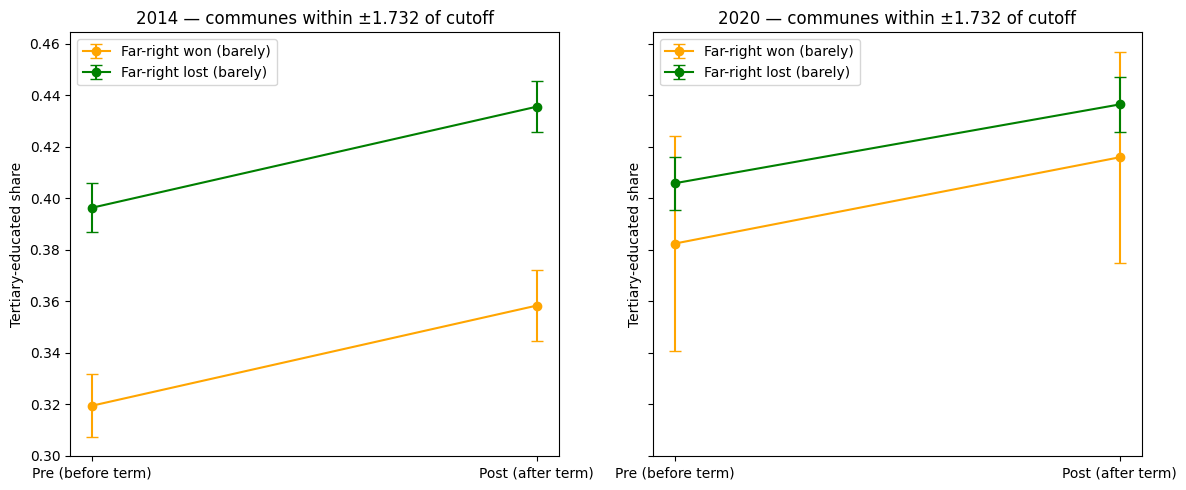

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, cyc in zip(axes, [2014, 2020]):
    sub = df[(df['election_year'] == cyc) & (df['d_50'].abs() <= bw)]
    g = sub.groupby('treat').agg(
        pre_mean=('skill_share_pre', 'mean'),
        pre_se=('skill_share_pre', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        post_mean=('skill_share_post', 'mean'),
        post_se=('skill_share_post', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    )

    for treat_val, label, color in [(1, 'Far-right won (barely)', 'orange'),
                                     (0, 'Far-right lost (barely)', 'green')]:
        means = [g.loc[treat_val, 'pre_mean'], g.loc[treat_val, 'post_mean']]
        ses   = [g.loc[treat_val, 'pre_se'],   g.loc[treat_val, 'post_se']]
        ax.errorbar([0, 1], means, yerr=ses, marker='o', label=label, color=color, capsize=4)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Pre (before term)', 'Post (after term)'])
    ax.set_title(f'{cyc} — communes within ±{bw} of cutoff')
    ax.set_ylabel('Tertiary-educated share')
    ax.legend()

plt.tight_layout()
plt.show()

## Extend Model with more years (for DiD like Plot)

In [11]:
# Helper functions (same function as in the Data cleaning script)
def compute_skill_share(df, year):
    """Fraction of residents with bac or higher, for a given census year."""
    educated = (df[f"bach{year}"] + df[f"suph{year}"] +    # men: bac + university
                df[f"bacf{year}"] + df[f"supf{year}"])     # women: bac + university
    total    = (educated +
                df[f"nodiph{year}"] + df[f"nodipf{year}"]) # add no-diploma residents
    return educated / total    

In [12]:
# Load the raw diploma file and reuse your own compute_skill_share() logic for every year
diplomes = pd.read_csv('diplomescommunes.csv', dtype={'codecommune': str}, low_memory=False)
diplomes['codecommune'] = diplomes['codecommune'].str.zfill(5)

In [13]:
years = range(2007, 2023)  # covers both pre- and post-election windows
skill_cols = []
for y in years:
    col = f'skill_share{y}'
    if col not in diplomes.columns:
        diplomes[col] = compute_skill_share(diplomes, y)
    skill_cols.append(col)

df = df.drop(columns=[c for c in skill_cols if c in df.columns], errors='ignore')
df = df.merge(diplomes[['codecommune'] + skill_cols],
              left_on='code_commune', right_on='codecommune', how='left', suffixes=('', '_dup'))

In [14]:
# 2020's post-window is truncated at 2022 (last year covered by the extrapolated series;
# the next real election, 2026, is outside our data horizon)
window_map = {
    2014: {'pre': (2009, 2013), 'post': (2015, 2019)},
    2020: {'pre': (2015, 2019), 'post': (2021, 2022)},
}

rows = []
for cyc, spans in window_map.items():
    sub = df[df['election_year'] == cyc]
    for y0, y1 in spans.values():
        for y in range(y0, y1 + 1):
            tmp = sub[['code_commune', 'd_50', 'treat']].copy()
            tmp['election_year'] = cyc
            tmp['rel_year'] = y - cyc
            tmp['skill_share'] = sub[f'skill_share{y}'].values
            rows.append(tmp)

event_panel = pd.concat(rows, ignore_index=True)

In [15]:
event_summary = (
    event_panel[event_panel['d_50'].abs() <= bw]
    .groupby(['election_year', 'treat', 'rel_year'])['skill_share']
    .agg(mean='mean', se=lambda x: x.std(ddof=1) / np.sqrt(len(x)), n='count')
    .reset_index()
)

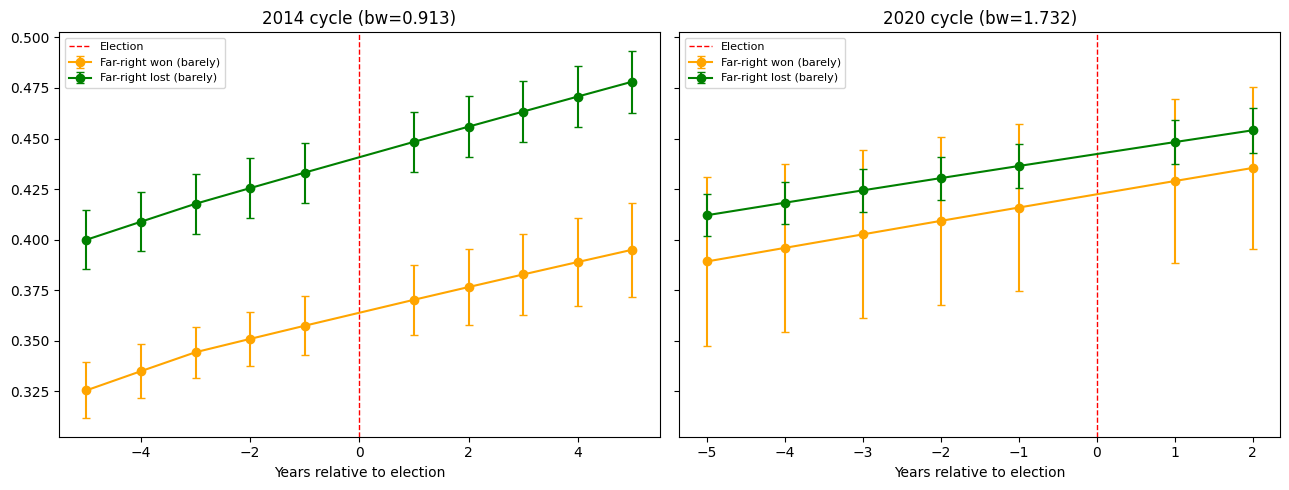

In [16]:
bw_dict = {2014: 0.913, 2020: 1.732}  # <- plug in your rdbwselect results from above

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, cyc in zip(axes, [2014, 2020]):
    bw = bw_dict[cyc]
    sub = event_panel[(event_panel['election_year'] == cyc) & (event_panel['d_50'].abs() <= bw)]
    g = (sub.groupby(['treat', 'rel_year'])['skill_share']
         .agg(mean='mean', se=lambda x: x.std(ddof=1)/np.sqrt(len(x)))
         .reset_index())

    for treat_val, label, color in [(1, 'Far-right won (barely)', 'orange'),
                                     (0, 'Far-right lost (barely)', 'green')]:
        gg = g[g['treat'] == treat_val].sort_values('rel_year')
        ax.errorbar(gg['rel_year'], gg['mean'], yerr=gg['se'], marker='o', label=label, color=color, capsize=3)

    ax.axvline(0, color='red', linestyle='--', linewidth=1, label='Election')
    ax.set_title(f'{cyc} cycle (bw={bw})')
    ax.set_xlabel('Years relative to election')
    ax.legend(fontsize=8)

plt.tight_layout(); plt.show()